In [29]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

digits = datasets.load_digits()
n_samples = len(digits.images)
img_shape = digits.images[0].shape

X_all = digits.images.reshape((n_samples, -1))
y_all = digits.target

print(
    f"Загружено образцов: {n_samples}, размерность вектора признаков: {X_all.shape[1]}"
)

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.3, random_state=42, stratify=y_all
)

best_k = 1
best_acc = 0.0
best_knn = None

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    if acc > best_acc:
        best_acc = acc
        best_k = k
        best_knn = knn

print(f"Оптимальное k: {best_k}, accuracy: {best_acc:.4f}")

Загружено образцов: 1797, размерность вектора признаков: 64
Оптимальное k: 1, accuracy: 0.9870


In [30]:
symbol_images = {digit: [] for digit in range(10)}
for img, target in zip(digits.images, digits.target):
    symbol_images[target].append(img)


def generate_text_sequence(
    num_words=3, min_word_len=2, max_word_len=3, alphabet=list(range(10))
):
    """Генерация строки из допустимых символов с разделением на слова."""
    words = []
    for _ in range(num_words):
        w_len = np.random.randint(min_word_len, max_word_len + 1)
        word = "".join(str(np.random.choice(alphabet)) for _ in range(w_len))
        words.append(word)
    return " ".join(words)


def generate_handwritten_image(
    text_string,
    symbol_images,
    char_spacing=2,
    space_width=14,
    bg_color=0.0,
):
    """Склейка изображений символов в строку с пробелами между словами."""
    image_parts = []
    h = 8

    for char in text_string:
        if char == " ":
            space_img = np.full((h, space_width), bg_color, dtype=np.float32)
            image_parts.append(space_img)
        else:
            digit = int(char)
            idx = np.random.randint(len(symbol_images[digit]))
            char_img = symbol_images[digit][idx].astype(np.float32)
            image_parts.append(char_img)

            spacer = np.full((h, char_spacing), bg_color, dtype=np.float32)
            image_parts.append(spacer)

    return np.hstack(image_parts)

In [31]:
def generate_handwritten_image(text_string, symbol_images, char_spacing=2, space_width=16, bg_color=0.0):
    image_parts = []
    h = 8

    for char in text_string:
        if char == " ":
            space_img = np.full((h, space_width), bg_color, dtype=np.float32)
            image_parts.append(space_img)
        else:
            digit = int(char)
            idx = np.random.randint(len(symbol_images[digit]))
            char_img = symbol_images[digit][idx].astype(np.float32)
            image_parts.append(char_img)

            spacer = np.full((h, char_spacing), bg_color, dtype=np.float32)
            image_parts.append(spacer)

    return np.hstack(image_parts)

In [32]:
def segment_and_extract_objects(image, space_threshold=10):
    img_norm = ((image - image.min()) / (image.max() - image.min() + 1e-6) * 255).astype(np.uint8)
    _, thresh = cv2.threshold(img_norm, 10, 255, cv2.THRESH_BINARY)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(thresh, connectivity=8)

    boxes = []
    for i in range(1, num_labels):
        x, y, w, h, area = stats[i]
        if area >= 3:
            boxes.append((x, y, w, h))

    boxes = sorted(boxes, key=lambda b: b[0])

    extracted_chars = []
    has_space_before = []

    for i, (x, y, w, h) in enumerate(boxes):
        is_space = False
        if i > 0:
            prev_x, _, prev_w, _ = boxes[i - 1]
            gap = x - (prev_x + prev_w)
            if gap >= space_threshold:
                is_space = True
        has_space_before.append(is_space)

        char_crop = image[:, x:x + w]

        char_canvas = np.zeros((8, 8), dtype=np.float32)
        if w <= 8:
            start_col = (8 - w) // 2
            char_canvas[:, start_col:start_col + w] = char_crop
        else:
            char_canvas = cv2.resize(char_crop, (8, 8), interpolation=cv2.INTER_AREA)

        extracted_chars.append(char_canvas)

    return extracted_chars, has_space_before, boxes


def recognize_sequence(image, classifier, space_threshold=10):
    chars, spaces, boxes = segment_and_extract_objects(image, space_threshold=space_threshold)

    recognized_text = []
    for char_img, is_space in zip(chars, spaces):
        if is_space:
            recognized_text.append(" ")

        char_vector = char_img.reshape(1, -1)
        pred_label = classifier.predict(char_vector)[0]
        recognized_text.append(str(pred_label))

    return "".join(recognized_text), boxes

Исходная строка (Ground Truth): '725 89 49'
Распознанная строка (Predicted):  '725 89 49'


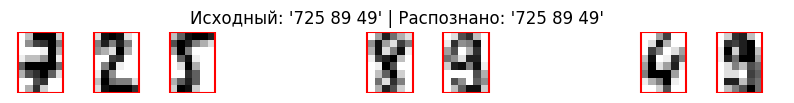

In [33]:
ground_truth_text = generate_text_sequence(num_words=3, min_word_len=2, max_word_len=3)
synthetic_image = generate_handwritten_image(ground_truth_text, symbol_images, space_width=16)
predicted_text, bboxes = recognize_sequence(synthetic_image, best_knn, space_threshold=10)

print(f"Исходная строка (Ground Truth): '{ground_truth_text}'")
print(f"Распознанная строка (Predicted):  '{predicted_text}'")

plt.figure(figsize=(10, 3))
plt.imshow(synthetic_image, cmap=plt.cm.gray_r)
for x, y, w, h in bboxes:
    rect = plt.Rectangle((x - 0.5, y - 0.5), w, h, fill=False, edgecolor='red', linewidth=1.5)
    plt.gca().add_patch(rect)

plt.title(f"Исходный: '{ground_truth_text}' | Распознано: '{predicted_text}'", fontsize=12)
plt.axis('off')
plt.show()